In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Everything works!")


Everything works!


In [6]:
import json
from urllib.request import urlopen

base = "https://www.smard.de/app/chart_data/410/DE/"
index = json.load(urlopen(base + "index_hour.json"))
timestamps = index["timestamps"][-52:]

rows = []
for ts in timestamps:
    data = json.load(urlopen(f"{base}410_DE_hour_{ts}.json"))
    rows += data["series"]

df = pd.DataFrame(rows, columns=["time", "consumption_mwh"])
df["time"] = pd.to_datetime(df["time"], unit="ms")
df = df.dropna()
df.head()

,time,consumption_mwh
0,2025-10-19 22:00:00,44837.75
1,2025-10-19 23:00:00,43480.46
2,2025-10-20 00:00:00,42838.74
3,2025-10-20 01:00:00,42957.28
4,2025-10-20 02:00:00,44618.61


In [7]:
print(df.shape)
df.describe()


(8635, 2)


,time,consumption_mwh
count,8635,8635.000000
mean,2026-04-17 19:00:00,53711.190090
min,2025-10-19 22:00:00,32598.390000
25%,2026-01-17 20:30:00,46161.700000
50%,2026-04-17 19:00:00,53762.380000
75%,2026-07-16 17:30:00,59760.725000
max,2026-10-14 16:00:00,78241.200000
std,NaN,9171.142605


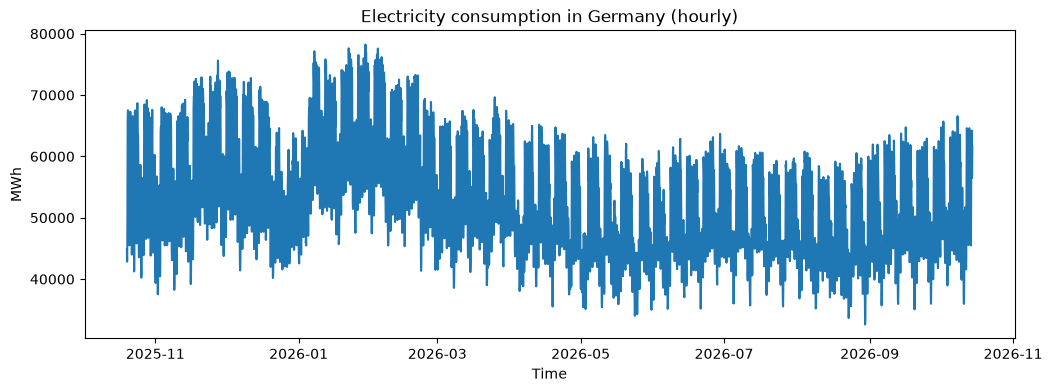

In [8]:
plt.figure(figsize=(12, 4))
plt.plot(df["time"], df["consumption_mwh"])
plt.title("Electricity consumption in Germany (hourly)")
plt.xlabel("Time")
plt.ylabel("MWh")
plt.show()


In [9]:
df["hour"] = df["time"].dt.hour
df["weekday"] = df["time"].dt.weekday
df["month"] = df["time"].dt.month
df.head()


,time,consumption_mwh,hour,weekday,month
0,2025-10-19 22:00:00,44837.75,22,6,10
1,2025-10-19 23:00:00,43480.46,23,6,10
2,2025-10-20 00:00:00,42838.74,0,0,10
3,2025-10-20 01:00:00,42957.28,1,0,10
4,2025-10-20 02:00:00,44618.61,2,0,10


In [10]:
features = ["hour", "weekday", "month"]

split = int(len(df) * 0.8)
train = df[:split]
test = df[split:]

X_train = train[features]
y_train = train["consumption_mwh"]
X_test = test[features]
y_test = test["consumption_mwh"]

print(len(train), len(test))


6908 1727


In [11]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Done!")

Done!


In [12]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

mae = mean_absolute_error(y_test, predictions)
mape = mean_absolute_percentage_error(y_test, predictions)

print(f"MAE: {mae:.0f} MWh")
print(f"MAPE: {mape * 100:.1f} %")

MAE: 2601 MWh
MAPE: 5.3 %


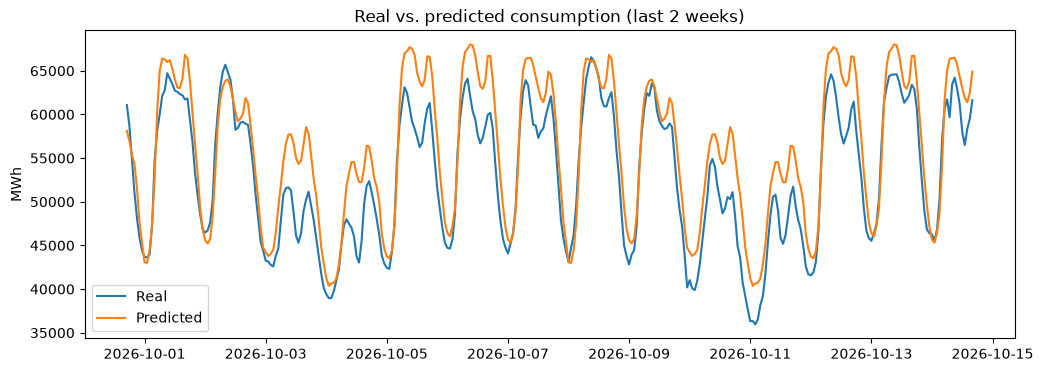

In [14]:
last = 24 * 14  # last 2 weeks

plt.figure(figsize=(12, 4))
plt.plot(test["time"][-last:], y_test[-last:], label="Real")
plt.plot(test["time"][-last:], predictions[-last:], label="Predicted")
plt.title("Real vs. predicted consumption (last 2 weeks)")
plt.ylabel("MWh")
plt.legend()
plt.savefig("forecast.png", bbox_inches="tight")
plt.show()